# Import libraries 

In [1]:
import h5py
#import archs4py as a4
import re
import numpy as np
import pandas as pd
import glob
import os
from sklearn.model_selection import train_test_split

# Function to load sample names from a text file into a variable

In [2]:
def load_sample_names(txt_file_path):
    """Load sample names from a text file"""
    with open(txt_file_path, 'r') as f:
        sample_names = [line.strip() for line in f if line.strip()]
    return sample_names

In [3]:
filtered_file = "/scratch/by2372/pipeline/ARCHS4/filtered_ARCHS4.h5"
tf_names = load_sample_names("/scratch/by2372/pipeline/tf_names.txt")
a4.ls(filtered_file)

class_name            str    | (63324,)
data                      
│ filtered_expression   float32 | (271742, 63324)
ensembl_id            str    | (271742,)
symbol                str    | (271742,)


# Filter the genes in the filtered ARCHS4 file to only contain TFs (ABLE RUN IN AN SBATCH Run_TFs_ARCHS4_filter_3.sbatch, BUT RAN BELOW AND WAITED ABOUT HALF AN HOUR)

In [4]:
# Read in the filtered ARCHS4 h5 and write out to a new h5
with h5py.File(filtered_file, "r") as fin, h5py.File('filtered_ARCHS4_TFs.h5', 'w') as fout:

    # Copy the class names into the new h5
    fin.copy("class_name", fout) 
    # Read in the gene symbol and ensembl IDs from the input h5 file
    symbols = fin["symbol"]
    ensembl_id = fin["ensembl_id"]

    # unpack the gene symbol names and decode bytes to strings
    symbols_unpack = symbols[:]
    if isinstance(symbols_unpack[0], bytes):
        symbols_unpack = [s.decode('utf-8') for s in symbols_unpack]

    # unapck the ensembl IDs and decode bytes to strings
    ensembl_unpack = ensembl_id[:]
    if isinstance(ensembl_unpack[0], bytes):
        ensembl_unpack = [s.decode('utf-8') for s in ensembl_unpack]

    # initialize the total number of genes in the input h5, an empty matched index list and the processing chunk size
    n_genes = len(symbols_unpack)
    tf_matched_indices = []
    chunk_size = 1000

    # iterate through indices of all genes in the input h5 by chunking through them
    for start_gene in range(0, n_genes, chunk_size):
        end_gene = min(start_gene + chunk_size, n_genes)
        chunk_symbols = symbols_unpack[start_gene:end_gene]

        # find the indices that match the list of known human TFs
        for i, sym in enumerate(chunk_symbols):
            if sym in tf_names:
                idx = start_gene + i
                tf_matched_indices.append(idx)

    tf_matched_indices.sort()
    print("Matched indices for TFs have been found")
    
    # Create output dataset for gene symbol in the output h5
    new_sym_dataset = fout.create_dataset(
        "symbol", 
        (len(tf_matched_indices), ),
        dtype=symbols.dtype,
        chunks=True
    )

    # Create output dataset for ensembl ID in the output h5
    new_ensembl_dataset = fout.create_dataset(
        "ensembl_id", 
        (len(tf_matched_indices), ),
        dtype=symbols.dtype,
        chunks=True
    )

    # convert symbols and ensembl IDs to np arrays
    symbols_arr = np.array(symbols_unpack)
    ensembl_arr = np.array(ensembl_unpack)

    # have only the matched indices be the new symbols and ensembl ID datasets
    new_sym_dataset[...] = symbols_arr[tf_matched_indices]
    new_ensembl_dataset[...] = ensembl_arr[tf_matched_indices]

    # Get dataset info
    expr_dataset = fin['data/filtered_expression']
    n_genes, n_samples = expr_dataset.shape

    # Create output dataset
    filtered_dataset = fout.create_dataset(
        "data/filtered_expression", 
        (len(tf_matched_indices), n_samples),
        dtype=expr_dataset.dtype,
        chunks=True
    )

    # do a chunking approach to chunk through the number of samples in 1000 chunks 
    iteration = 0
    for start_sample in range(0, n_samples, chunk_size):
        end_sample = min(start_sample + chunk_size, n_samples)
        data_chunk = expr_dataset[tf_matched_indices, start_sample:end_sample]
        filtered_dataset[:, start_sample:end_sample] = data_chunk
        print("Iteration " + str(iteration)+ " is done.")
        iteration += 1


Matched indices for TFs have been found
Iteration 0 is done.
Iteration 1 is done.
Iteration 2 is done.
Iteration 3 is done.
Iteration 4 is done.
Iteration 5 is done.
Iteration 6 is done.
Iteration 7 is done.
Iteration 8 is done.
Iteration 9 is done.
Iteration 10 is done.
Iteration 11 is done.
Iteration 12 is done.
Iteration 13 is done.
Iteration 14 is done.
Iteration 15 is done.
Iteration 16 is done.
Iteration 17 is done.
Iteration 18 is done.
Iteration 19 is done.
Iteration 20 is done.
Iteration 21 is done.
Iteration 22 is done.
Iteration 23 is done.
Iteration 24 is done.
Iteration 25 is done.
Iteration 26 is done.
Iteration 27 is done.
Iteration 28 is done.
Iteration 29 is done.
Iteration 30 is done.
Iteration 31 is done.
Iteration 32 is done.
Iteration 33 is done.
Iteration 34 is done.
Iteration 35 is done.
Iteration 36 is done.
Iteration 37 is done.
Iteration 38 is done.
Iteration 39 is done.
Iteration 40 is done.
Iteration 41 is done.
Iteration 42 is done.
Iteration 43 is done.
It

In [5]:
filtered_file_tf = "/scratch/by2372/pipeline/ARCHS4/filtered_ARCHS4_TFs.h5"
#redownload the most recent transcript file
a4.ls(filtered_file_tf)

class_name            str    | (63324,)
data                      
│ filtered_expression   float32 | (13146, 63324)
ensembl_id            str    | (13146,)
symbol                str    | (13146,)


# Function for chunking through samples to output into new expression dataset

In [6]:
def chunk_samples(chunk_size, n_samples, n_genes, output, input):
    iteration = 0
    for start_sample in range(0, n_samples, chunk_size):
        end_sample = min(start_sample + chunk_size, n_samples)

        for start_gene in range(0, n_genes, chunk_size):
            end_gene = min(start_gene + chunk_size, n_genes)

            # Read a chunk of the input matrix
            data_chunk = input[start_sample:end_sample, start_gene:end_gene]

            # Write the chunk to the output dataset
            output[start_sample:end_sample, start_gene:end_gene] = data_chunk

        print("Iteration " + str(iteration) + " (samples " + str(start_sample) + "-" + str(end_sample) + ") is done.")
        iteration += 1

In [7]:
def chunk_class(chunk_size,n_samples,output,input):
    iteration = 0
    for start_sample in range(0, n_samples, chunk_size):
        end_sample = min(start_sample + chunk_size, n_samples)
        data_chunk = input[start_sample:end_sample]
        output[start_sample:end_sample] = data_chunk
        print("Iteration " + str(iteration)+ " is done.")
        iteration += 1

# Make into a H5 for ML training and testing

In [8]:
# Make Rows be the samples and the columns be the transcripts
# make it into a data frame and export as H5
with h5py.File(filtered_file_tf, "r") as fin, h5py.File('filtered_training.h5', 'w') as ftrain, h5py.File('filtered_testing.h5', 'w') as ftest:

    # Navigate to the metadata group for class names, gene symbols, and ensembl ID
    class_name_ds = fin['class_name']
    ensembl_id = fin["ensembl_id"]
    symbols = fin["symbol"]

    # Read all names and decode bytes to strings
    symbols_unpack = symbols[:]
    if isinstance(symbols_unpack[0], bytes):
        symbols_unpack = [s.decode('utf-8') for s in symbols_unpack]

    # Read all names and decode bytes to strings
    class_names = class_name_ds[:]
    if isinstance(class_names[0], bytes):
        class_names = [s.decode('utf-8') for s in class_names]

    ensembl_unpack = ensembl_id[:]
    if isinstance(ensembl_unpack[0], bytes):
        ensembl_unpack = [s.decode('utf-8') for s in ensembl_unpack]

    # Navigate to the metadata group for the expression data
    expression = fin["data/filtered_expression"]

    # Transpose expression data so that rows are samples and columns are transcripts
    expression_data = expression[:, :] 
    expression_data = expression_data.T
    print("Expression data has been transposed\n")

    # Make the transcript ID be the symbol _ ensembl ID
    transcript_ID = []
    for idx, sym in enumerate(symbols_unpack):
        ID = sym + "_" + ensembl_unpack[idx]
        transcript_ID.append(ID)

    filtered_df = pd.DataFrame(expression_data,index = class_names, columns = transcript_ID)
    filtered_df['cell_identity'] = class_names

    # Count occurrences of each cell_identity
    cell_identity_counts = filtered_df['cell_identity'].value_counts()
    print(cell_identity_counts)

    # Create a boolean mask to filter rows with cell_identity occurring more than once
    mask = filtered_df['cell_identity'].isin(cell_identity_counts[cell_identity_counts > 1].index)

    # Filter the DataFrame using the mask
    filtered_df = filtered_df[mask]

    # Seperate the ensmbl ids from the cell_identity column
    TFs = filtered_df.columns.drop(['cell_identity'])

    # Set predictors and predicted
    X = np.array(filtered_df[TFs])
    y = np.array(filtered_df['cell_identity'])

    # Train - test split with stratification and shuffling
    ### THIS LOADS IN THE WHOLE H5 FILE TO SPLIT
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=5, stratify=y,shuffle = True)

    # Create output dataset
    X_train_out = ftrain.create_dataset(
        "expression", 
        (X_train.shape[0], X_train.shape[1]),
        dtype=expression.dtype,
        chunks=True
    )
    print("Starting X Train output into H5")
    chunk_samples(1000,X_train.shape[0],X_train.shape[1],X_train_out,X_train)
    print("X Train output successfully")

    y_train_out = ftrain.create_dataset(
        "label",
        len(y_train),
        dtype=h5py.string_dtype(encoding='utf-8'),
        chunks = True
    )
    print("Starting y train output into H5")
    chunk_class(1000,len(y_train),y_train_out,y_train)
    print("y Train output successfully")

    TF_ID_out = ftrain.create_dataset(
        "TF_ID",
        len(transcript_ID),
        dtype=h5py.string_dtype(encoding='utf-8'),
        chunks = True
    )
    print("Starting TF IDs output into training H5")
    chunk_class(1000,len(transcript_ID),TF_ID_out,transcript_ID)
    print("TF ID output successfully")
    
    ###export X_test, y_test with Transcript_ID or TFs to an h5
    
    X_test_out = ftest.create_dataset(
        "expression", 
        (X_test.shape[0], X_test.shape[1]),
        dtype=expression.dtype,
        chunks=True
    )
    print("Starting X Test output into H5")
    chunk_samples(1000,X_test.shape[0],X_test.shape[1],X_test_out,X_test)
    print("X test output successfully")

    y_test_out = ftest.create_dataset(
        "label",
        len(y_test),
        dtype=h5py.string_dtype(encoding='utf-8'),
        chunks = True
    )
    print("Starting y test output into H5")
    chunk_class(1000,len(y_test),y_test_out,y_test)
    print("y test output successfully")

    TF_ID_out = ftest.create_dataset(
        "TF_ID",
        len(transcript_ID),
        dtype=h5py.string_dtype(encoding='utf-8'),
        chunks = True
    )
    print("Starting TF IDs output into testing H5")
    chunk_class(1000,len(transcript_ID),TF_ID_out,transcript_ID)
    print("TF ID output successfully")


    

Expression data has been transposed

cell_identity
iPSC             15215
TCELL            14029
Fibroblast        9219
Monocyte          4940
NEURON            4315
Macrophage        3649
Cardiomyocyte     3147
Hepatocyte        2327
BCELL             1851
Dendritic         1367
Leukocyte          925
Myoblast           840
Astrocyte          728
Microglia          603
Osteoblast         169
Name: count, dtype: int64
Starting X Train output into H5
Iteration 0 (samples 0-1000) is done.
Iteration 1 (samples 1000-2000) is done.
Iteration 2 (samples 2000-3000) is done.
Iteration 3 (samples 3000-4000) is done.
Iteration 4 (samples 4000-5000) is done.
Iteration 5 (samples 5000-6000) is done.
Iteration 6 (samples 6000-7000) is done.
Iteration 7 (samples 7000-8000) is done.
Iteration 8 (samples 8000-9000) is done.
Iteration 9 (samples 9000-10000) is done.
Iteration 10 (samples 10000-11000) is done.
Iteration 11 (samples 11000-12000) is done.
Iteration 12 (samples 12000-13000) is done.
Iterat

In [9]:
train_file = "/scratch/by2372/pipeline/ARCHS4/filtered_training.h5"
#redownload the most recent transcript file
a4.ls(train_file)

TF_ID                 str    | (13146,)
expression            float32 | (47493, 13146)
label                 str    | (47493,)


In [10]:
test_file = "/scratch/by2372/pipeline/ARCHS4/filtered_testing.h5"
#redownload the most recent transcript file
a4.ls(test_file)

TF_ID                 str    | (13146,)
expression            float32 | (15831, 13146)
label                 str    | (15831,)


In [11]:
pd.Series(y_test).value_counts()

iPSC             3804
TCELL            3507
Fibroblast       2305
Monocyte         1235
NEURON           1079
Macrophage        912
Cardiomyocyte     787
Hepatocyte        582
BCELL             463
Dendritic         342
Leukocyte         231
Myoblast          210
Astrocyte         182
Microglia         150
Osteoblast         42
Name: count, dtype: int64

In [12]:
pd.Series(y_train).value_counts()

iPSC             11411
TCELL            10522
Fibroblast        6914
Monocyte          3705
NEURON            3236
Macrophage        2737
Cardiomyocyte     2360
Hepatocyte        1745
BCELL             1388
Dendritic         1025
Leukocyte          694
Myoblast           630
Astrocyte          546
Microglia          453
Osteoblast         127
Name: count, dtype: int64

# Load in the training data (use when you dont want the H5 output code to run again)

In [2]:
f_train = h5py.File("/scratch/by2372/pipeline/ARCHS4/filtered_training.h5", 'r')
expression_train = f_train['expression'][...]
label_train = f_train['label'][...]
f_train.close()
f_test = h5py.File("/scratch/by2372/pipeline/ARCHS4/filtered_testing.h5", 'r')
expression_test = f_test['expression'][...]
label_test = f_test['label'][...]

TFs = f_test['TF_ID'][...]

# Read all names and decode bytes to strings
if isinstance(label_train[0], bytes):
    label_train = [s.decode('utf-8') for s in label_train]

# Read all names and decode bytes to strings
if isinstance(label_test[0], bytes):
    label_test = [s.decode('utf-8') for s in label_test]

# Read all names and decode bytes to strings
if isinstance(TFs[0], bytes):
    TFs = [s.decode('utf-8') for s in TFs]

f_test.close()

# Random Oversampler on Training Data

In [3]:
from imblearn.over_sampling import RandomOverSampler
from collections import Counter

ros = RandomOverSampler(random_state=42)
expression_ros, label_ros = ros.fit_resample(expression_train,label_train)

print("Original class distribution:", Counter(label_train))
print("Resampled class distribution:", Counter(label_ros))

Original class distribution: Counter({'iPSC': 11411, 'TCELL': 10522, 'Fibroblast': 6914, 'Monocyte': 3705, 'NEURON': 3236, 'Macrophage': 2737, 'Cardiomyocyte': 2360, 'Hepatocyte': 1745, 'BCELL': 1388, 'Dendritic': 1025, 'Leukocyte': 694, 'Myoblast': 630, 'Astrocyte': 546, 'Microglia': 453, 'Osteoblast': 127})
Resampled class distribution: Counter({'Monocyte': 11411, 'iPSC': 11411, 'TCELL': 11411, 'NEURON': 11411, 'Fibroblast': 11411, 'Cardiomyocyte': 11411, 'Macrophage': 11411, 'BCELL': 11411, 'Dendritic': 11411, 'Microglia': 11411, 'Myoblast': 11411, 'Hepatocyte': 11411, 'Astrocyte': 11411, 'Leukocyte': 11411, 'Osteoblast': 11411})


# SMOTE on Training Data

In [4]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=0,k_neighbors = 1)
expression_SMOTE, label_SMOTE = smote.fit_resample(expression_train,label_train)

print("Original class distribution:", Counter(label_train))
print("Resampled class distribution:", Counter(label_SMOTE))

Original class distribution: Counter({'iPSC': 11411, 'TCELL': 10522, 'Fibroblast': 6914, 'Monocyte': 3705, 'NEURON': 3236, 'Macrophage': 2737, 'Cardiomyocyte': 2360, 'Hepatocyte': 1745, 'BCELL': 1388, 'Dendritic': 1025, 'Leukocyte': 694, 'Myoblast': 630, 'Astrocyte': 546, 'Microglia': 453, 'Osteoblast': 127})
Resampled class distribution: Counter({'Monocyte': 11411, 'iPSC': 11411, 'TCELL': 11411, 'NEURON': 11411, 'Fibroblast': 11411, 'Cardiomyocyte': 11411, 'Macrophage': 11411, 'BCELL': 11411, 'Dendritic': 11411, 'Microglia': 11411, 'Myoblast': 11411, 'Hepatocyte': 11411, 'Astrocyte': 11411, 'Leukocyte': 11411, 'Osteoblast': 11411})


# BLSMOTE on Training Data

In [3]:
from imblearn.over_sampling import BorderlineSMOTE
from collections import Counter

BLsmote = BorderlineSMOTE(random_state=1,k_neighbors = 1)
expression_BLSMOTE, label_BLSMOTE = BLsmote.fit_resample(expression_train,label_train)

print("Original class distribution:", Counter(label_train))
print("Resampled class distribution:", Counter(label_BLSMOTE))

Original class distribution: Counter({'iPSC': 11411, 'TCELL': 10522, 'Fibroblast': 6914, 'Monocyte': 3705, 'NEURON': 3236, 'Macrophage': 2737, 'Cardiomyocyte': 2360, 'Hepatocyte': 1745, 'BCELL': 1388, 'Dendritic': 1025, 'Leukocyte': 694, 'Myoblast': 630, 'Astrocyte': 546, 'Microglia': 453, 'Osteoblast': 127})
Resampled class distribution: Counter({'Monocyte': 11411, 'iPSC': 11411, 'TCELL': 11411, 'NEURON': 11411, 'Fibroblast': 11411, 'Cardiomyocyte': 11411, 'Macrophage': 11411, 'BCELL': 11411, 'Dendritic': 11411, 'Microglia': 11411, 'Myoblast': 11411, 'Hepatocyte': 11411, 'Astrocyte': 11411, 'Leukocyte': 11411, 'Osteoblast': 11411})


# Training Neural Network with Pytorch

In [3]:
from tensorflow import keras
from sklearn.preprocessing import LabelEncoder
import tensorflow as tef
from keras import optimizers
from keras import losses
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, KernelPCA
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (auc, roc_curve, roc_auc_score)

2025-12-04 16:44:52.602428: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2025-12-04 16:44:52.602901: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-12-04 16:44:52.657775: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-12-04 16:44:56.198157: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To tur

## Perform PCA analysis on the Training Data set and Generate PCA Plot

In [4]:
# normalize feature values
express_train_scale = StandardScaler().fit_transform(expression_train)
# Make normalized data into a data frame
express_train_scale_df = pd.DataFrame(express_train_scale, columns = TFs)
PCA_train = PCA(n_components = 2)
PC_expression_train = PCA_train.fit_transform(express_train_scale_df)

PC_expression_train_df = pd.DataFrame(data = PC_expression_train, columns = ['PC1','PC2'])

/state/partition1/job-3018272/ipykernel_1598521/2968141013.py:9: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colors = plt.cm.get_cmap('viridis',len(unique_labels))


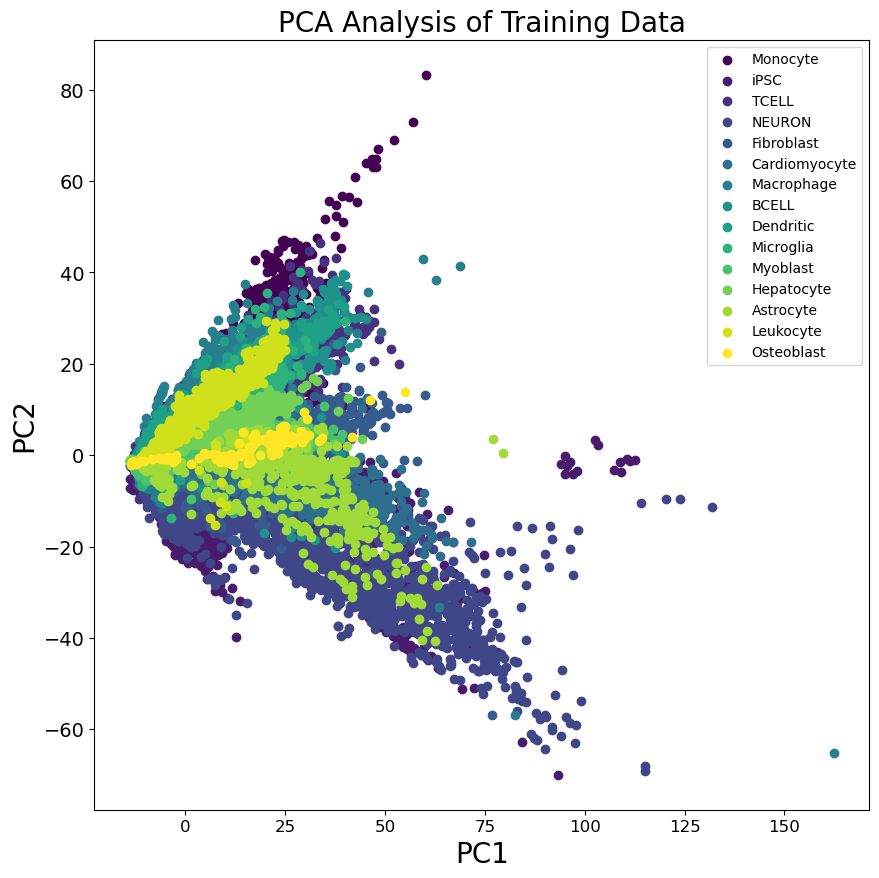

In [5]:
plt.figure(figsize = (10,10))
plt.xticks(fontsize = 12)
plt.yticks(fontsize = 14)
plt.xlabel('PC1', fontsize = 20)
plt.ylabel('PC2', fontsize = 20)
plt.title('PCA Analysis of Training Data',fontsize = 20)
label_train_df = pd.DataFrame(data = label_train, columns = ['labels'])
unique_labels = label_train_df['labels'].unique()
colors = plt.cm.get_cmap('viridis',len(unique_labels))

for i, s_type in enumerate(unique_labels):
    indices = label_train_df['labels'] == s_type
    plt.scatter(PC_expression_train_df.loc[indices, 'PC1'],
                PC_expression_train_df.loc[indices, 'PC2'],
                color=colors(i), label=s_type)

plt.legend()
plt.show()

## Perform PCA analysis on the Testing Data set and Generate PCA Plot

In [6]:
# normalize feature values
express_test_scale = StandardScaler().fit_transform(expression_test)
# Make normalized data into a data frame
express_test_scale_df = pd.DataFrame(express_test_scale, columns = TFs)
PCA_test = PCA(n_components = 2)
PC_expression_test = PCA_test.fit_transform(express_test_scale_df)

PC_expression_test_df = pd.DataFrame(data = PC_expression_test, columns = ['PC1','PC2'])

/state/partition1/job-3018272/ipykernel_1598521/762438255.py:9: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colors = plt.cm.get_cmap('viridis',len(unique_labels_test))


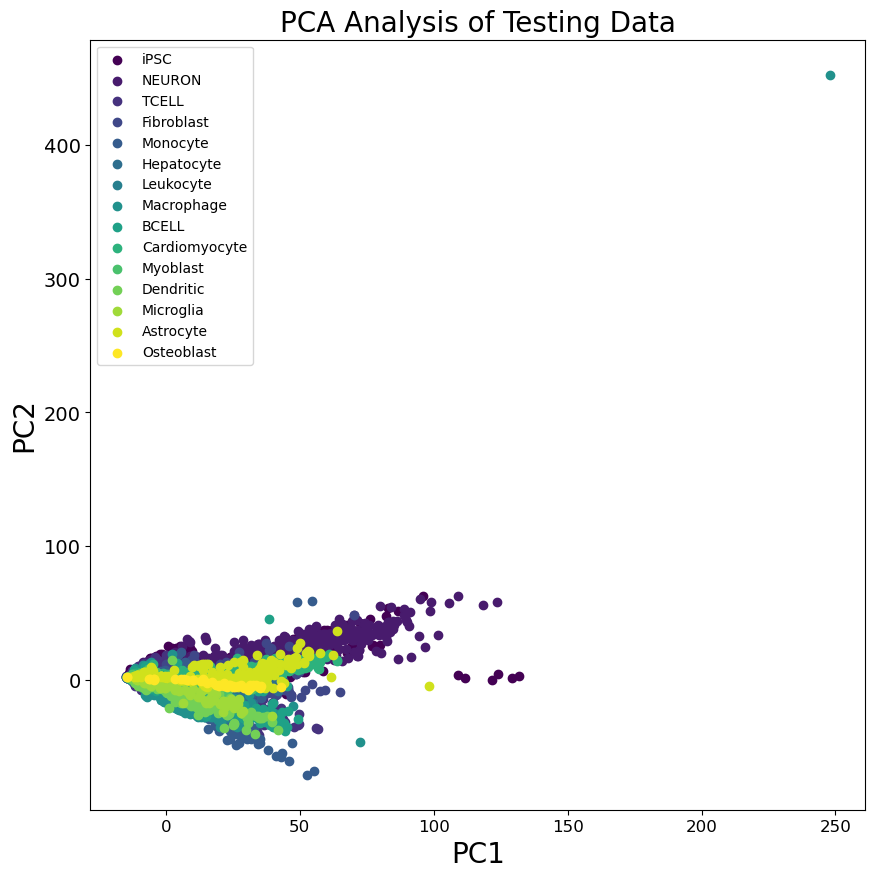

In [7]:
plt.figure(figsize = (10,10))
plt.xticks(fontsize = 12)
plt.yticks(fontsize = 14)
plt.xlabel('PC1', fontsize = 20)
plt.ylabel('PC2', fontsize = 20)
plt.title('PCA Analysis of Testing Data',fontsize = 20)
label_test_df = pd.DataFrame(data = label_test, columns = ['labels'])
unique_labels_test = label_test_df['labels'].unique()
colors = plt.cm.get_cmap('viridis',len(unique_labels_test))

for i, s_type in enumerate(unique_labels_test):
    indices = label_test_df['labels'] == s_type
    plt.scatter(PC_expression_test_df.loc[indices, 'PC1'],
                PC_expression_test_df.loc[indices, 'PC2'],
                color=colors(i), label=s_type)

plt.legend()
plt.show()

## Create a function for Neural Network Training

In [5]:
def NN_training(X_train,y_train,X_test,y_test,TFS,name):

    keras.utils.set_random_seed(10)   
    
    num_unique_y = len(set(y_train))

    le = LabelEncoder()
    
    # Fit on training labels (strings) and transform them to integers
    label_train_int = le.fit_transform(y_train)
    
    # Use the same encoder to transform test labels
    label_test_int = le.transform(y_test)
    
    # Best model in magnussen paper was 2 layers of 250 nodes
    model = keras.Sequential([
        keras.layers.Input(shape=(len(TFs),)),  # there are 13146 TFs
        keras.layers.Dense(250, activation='elu'),
        keras.layers.Dense(250, activation='elu'),
        keras.layers.Dense(num_unique_y, activation='softmax')  # For multiclass classification
    ])

    callback = keras.callbacks.EarlyStopping(monitor='val_loss', patience = 3)
    
    adam = optimizers.Adam(
        learning_rate=0.001,
        beta_1=0.9,
        beta_2=0.999,
        weight_decay=0.01  # replaces old `decay`
    )
    model.compile(loss='sparse_categorical_crossentropy',optimizer=adam,metrics=['accuracy'], )
    model.fit(X_train, label_train_int, batch_size=50, epochs=100, verbose=1, validation_split = 0.1, callbacks = [callback])

    model.save("/scratch/by2372/pipeline/ARCHS4/" + name + "_trained_NN.keras")

    np.save("/scratch/by2372/pipeline/ARCHS4/" + name + "_class_names.npy", le.classes_)

    loss, accuracy = model.evaluate(X_test, label_test_int, verbose=1)

    # Predictions on test set
    y_prob = model.predict(X_test)
    y_pred = np.argmax(y_prob, axis=1)

    # Calculate F1 Metrics
    f1_macro = f1_score(label_test_int, y_pred, average='macro')
    f1_weighted = f1_score(label_test_int, y_pred, average='weighted')
    f1_micro = f1_score(label_test_int,y_pred,average = 'micro')

     # binarize the classes
    cell_classes = np.unique(np.concatenate((label_train_int, label_test_int)))
    y_test_bin = label_binarize(label_test_int, classes=cell_classes)

    fpr = dict()
    tpr = dict()
    roc_auc = dict()
    roc_auc_labeled = dict()

    # One vs. rest AUC calculation for multiclass data
    for i in range(len(cell_classes)):
        cur_class = cell_classes[i]
        fpr[cur_class], tpr[cur_class], _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
        roc_auc[cur_class] = auc(fpr[cur_class], tpr[cur_class])
        # Inverse transform the label encoder to get the class label once again
        class_label = le.inverse_transform([cur_class])[0]
        roc_auc_labeled[class_label] = roc_auc[cur_class]
        print(f"AUC for class {cur_class}: {roc_auc[cur_class]:.2f}")

    # compute micro-average ROC curve and ROC area
    fpr["micro"], tpr["micro"],_=roc_curve(y_test_bin.ravel(),y_prob.ravel())
    roc_auc_labeled["micro"] = auc(fpr["micro"],tpr["micro"])   

    return {
    "f1_macro": f1_macro,
    "f1_weighted": f1_weighted,
    "f1_micro": f1_micro,
    "roc_auc_micro": roc_auc_labeled["micro"],
    "roc_auc_per_class": roc_auc_labeled,
    "loss" : loss,
    "accuracy" : accuracy
    }

# Train NN on unbalanced Data

In [7]:
unbal_metrics = NN_training(expression_train,label_train,expression_test,label_test,TFs,"unbalanced")


2025-11-24 20:35:27.418975: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epoch 1/100
855/855 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.8949 - loss: 2.1448 - val_accuracy: 0.9362 - val_loss: 0.7837
Epoch 2/100
855/855 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.9593 - loss: 0.4321 - val_accuracy: 0.9482 - val_loss: 0.5981
Epoch 3/100
855/855 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.9734 - loss: 0.2205 - val_accuracy: 0.9539 - val_loss: 0.7634
Epoch 4/100
855/855 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.9767 - loss: 0.2142 - val_accuracy: 0.9501 - val_loss: 1.1130
Epoch 5/100
855/855 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.9797 - loss: 0.2059 - val_accuracy: 0.9585 - val_loss: 0.9201
495/495 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9586 - loss: 0.9614
495/495 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
AUC for class 0: 0.99
AUC for class 1: 0.97
AUC for class 2: 1.00
AUC for class 3: 0.97
AUC for class 4: 1.00
AUC for class 5: 1.00
AUC for class 6: 1.00
AUC for class 7: 1.00
AUC for class 8: 0.99
AUC for class 9: 1.00
AUC for c

In [8]:
unbal_metrics

{'f1_macro': 0.931052431135888,
 'f1_weighted': 0.9582452558770517,
 'f1_micro': 0.9585623144463394,
 'roc_auc_micro': 0.9945607476942575,
 'roc_auc_per_class': {'Astrocyte': 0.9924307911399739,
  'BCELL': 0.9715780624067514,
  'Cardiomyocyte': 0.9950290667916254,
  'Dendritic': 0.9730000804192676,
  'Fibroblast': 0.9955927412875276,
  'Hepatocyte': 0.9999109850930454,
  'Leukocyte': 0.9965284715284715,
  'Macrophage': 0.9955142638669869,
  'Microglia': 0.9946865633569288,
  'Monocyte': 0.9978425679266574,
  'Myoblast': 0.9824710935523304,
  'NEURON': 0.9898897483811435,
  'Osteoblast': 0.9969825285234747,
  'TCELL': 0.9941116862116635,
  'iPSC': 0.995873659485226,
  'micro': 0.9945607476942575},
 'loss': 0.9613928198814392,
 'accuracy': 0.9585623145103455}

# Train NN on RO Data

In [9]:
RO_metrics = NN_training(expression_ros,label_ros,expression_test,label_test,TFs,"RO")


Epoch 1/100
3081/3081 ━━━━━━━━━━━━━━━━━━━━ 48s 15ms/step - accuracy: 0.9506 - loss: 0.7852 - val_accuracy: 0.8991 - val_loss: 1.1276
Epoch 2/100
3081/3081 ━━━━━━━━━━━━━━━━━━━━ 48s 16ms/step - accuracy: 0.9814 - loss: 0.2091 - val_accuracy: 0.9676 - val_loss: 0.4726
Epoch 3/100
3081/3081 ━━━━━━━━━━━━━━━━━━━━ 48s 15ms/step - accuracy: 0.9884 - loss: 0.1809 - val_accuracy: 0.9680 - val_loss: 0.4125
Epoch 4/100
3081/3081 ━━━━━━━━━━━━━━━━━━━━ 47s 15ms/step - accuracy: 0.9892 - loss: 0.1374 - val_accuracy: 0.9815 - val_loss: 0.5673
Epoch 5/100
3081/3081 ━━━━━━━━━━━━━━━━━━━━ 47s 15ms/step - accuracy: 0.9924 - loss: 0.1309 - val_accuracy: 0.9062 - val_loss: 0.6208
Epoch 6/100
3081/3081 ━━━━━━━━━━━━━━━━━━━━ 47s 15ms/step - accuracy: 0.9932 - loss: 0.1022 - val_accuracy: 0.9711 - val_loss: 0.3757
Epoch 7/100
3081/3081 ━━━━━━━━━━━━━━━━━━━━ 47s 15ms/step - accuracy: 0.9944 - loss: 0.1172 - val_accuracy: 0.9775 - val_loss: 0.3612
Epoch 8/100
3081/3081 ━━━━━━━━━━━━━━━━━━━━ 48s 15ms/step - accuracy: 

In [10]:
RO_metrics

{'f1_macro': 0.9502870416905983,
 'f1_weighted': 0.9681682076230698,
 'f1_micro': 0.9681637293916998,
 'roc_auc_micro': 0.9937358313379335,
 'roc_auc_per_class': {'Astrocyte': 0.9908395649337562,
  'BCELL': 0.9720596246105622,
  'Cardiomyocyte': 0.9915620237392593,
  'Dendritic': 0.9879544774087932,
  'Fibroblast': 0.9942962425061976,
  'Hepatocyte': 0.9999471544413142,
  'Leukocyte': 0.9969584582084581,
  'Macrophage': 0.9974752185191851,
  'Microglia': 0.999527241034798,
  'Monocyte': 0.9986660701229219,
  'Myoblast': 0.9812297853012276,
  'NEURON': 0.9856738923824784,
  'Osteoblast': 0.9991035048511774,
  'TCELL': 0.9903878893115611,
  'iPSC': 0.9952811549932735,
  'micro': 0.9937358313379335},
 'loss': 3.4203553199768066,
 'accuracy': 0.9681637287139893}

# Train NN on SMOTE Data

In [11]:
SMOTE_metrics = NN_training(expression_SMOTE,label_SMOTE,expression_test,label_test,TFs,"SMOTE")


Epoch 1/100
3081/3081 ━━━━━━━━━━━━━━━━━━━━ 49s 16ms/step - accuracy: 0.9548 - loss: 0.6516 - val_accuracy: 0.9242 - val_loss: 0.4604
Epoch 2/100
3081/3081 ━━━━━━━━━━━━━━━━━━━━ 46s 15ms/step - accuracy: 0.9836 - loss: 0.2012 - val_accuracy: 0.9623 - val_loss: 0.3015
Epoch 3/100
3081/3081 ━━━━━━━━━━━━━━━━━━━━ 45s 15ms/step - accuracy: 0.9872 - loss: 0.1553 - val_accuracy: 0.9759 - val_loss: 0.5757
Epoch 4/100
3081/3081 ━━━━━━━━━━━━━━━━━━━━ 45s 15ms/step - accuracy: 0.9904 - loss: 0.1137 - val_accuracy: 0.9447 - val_loss: 0.2272
Epoch 5/100
3081/3081 ━━━━━━━━━━━━━━━━━━━━ 45s 15ms/step - accuracy: 0.9916 - loss: 0.1046 - val_accuracy: 0.9659 - val_loss: 0.3180
Epoch 6/100
3081/3081 ━━━━━━━━━━━━━━━━━━━━ 46s 15ms/step - accuracy: 0.9928 - loss: 0.1239 - val_accuracy: 0.9034 - val_loss: 0.5299
Epoch 7/100
3081/3081 ━━━━━━━━━━━━━━━━━━━━ 46s 15ms/step - accuracy: 0.9938 - loss: 0.1646 - val_accuracy: 0.7206 - val_loss: 2.5719
495/495 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9639 - loss: 2

In [12]:
SMOTE_metrics

{'f1_macro': 0.9310647873424612,
 'f1_weighted': 0.9640552459561549,
 'f1_micro': 0.9638683595477229,
 'roc_auc_micro': 0.9937116180127432,
 'roc_auc_per_class': {'Astrocyte': 0.9970022309468919,
  'BCELL': 0.9770749547740503,
  'Cardiomyocyte': 0.996045399399373,
  'Dendritic': 0.9879936487656398,
  'Fibroblast': 0.994009368315477,
  'Hepatocyte': 0.9999535770358667,
  'Leukocyte': 0.9998563936063937,
  'Macrophage': 0.9946933837459122,
  'Microglia': 0.9996058924813469,
  'Monocyte': 0.9968566619660647,
  'Myoblast': 0.9736144262454998,
  'NEURON': 0.9897840464980228,
  'Osteoblast': 0.9949799287629424,
  'TCELL': 0.9867005914910107,
  'iPSC': 0.9959728819934329,
  'micro': 0.9937116180127432},
 'loss': 2.2977585792541504,
 'accuracy': 0.9638683795928955}

# Train NN on BLSMOTE Data

In [6]:
BLSMOTE_metrics = NN_training(expression_BLSMOTE,label_BLSMOTE,expression_test,label_test,TFs,"BLSMOTE")


2025-11-24 21:00:35.309712: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epoch 1/100
3081/3081 ━━━━━━━━━━━━━━━━━━━━ 47s 15ms/step - accuracy: 0.9556 - loss: 0.7044 - val_accuracy: 0.8669 - val_loss: 1.3420
Epoch 2/100
3081/3081 ━━━━━━━━━━━━━━━━━━━━ 45s 15ms/step - accuracy: 0.9831 - loss: 0.1830 - val_accuracy: 0.8723 - val_loss: 1.0263
Epoch 3/100
3081/3081 ━━━━━━━━━━━━━━━━━━━━ 46s 15ms/step - accuracy: 0.9879 - loss: 0.1362 - val_accuracy: 0.9179 - val_loss: 1.0914
Epoch 4/100
3081/3081 ━━━━━━━━━━━━━━━━━━━━ 47s 15ms/step - accuracy: 0.9905 - loss: 0.1817 - val_accuracy: 0.9377 - val_loss: 0.6365
Epoch 5/100
3081/3081 ━━━━━━━━━━━━━━━━━━━━ 47s 15ms/step - accuracy: 0.9929 - loss: 0.1550 - val_accuracy: 0.9880 - val_loss: 0.0254
Epoch 6/100
3081/3081 ━━━━━━━━━━━━━━━━━━━━ 47s 15ms/step - accuracy: 0.9937 - loss: 0.0825 - val_accuracy: 0.9829 - val_loss: 0.0715
Epoch 7/100
3081/3081 ━━━━━━━━━━━━━━━━━━━━ 47s 15ms/step - accuracy: 0.9940 - loss: 0.1256 - val_accuracy: 0.8535 - val_loss: 1.0939
Epoch 8/100
3081/3081 ━━━━━━━━━━━━━━━━━━━━ 46s 15ms/step - accuracy: 

In [7]:
BLSMOTE_metrics

{'f1_macro': 0.9524956881666033,
 'f1_weighted': 0.9662781229642788,
 'f1_micro': 0.9663318804876508,
 'roc_auc_micro': 0.9934706973223956,
 'roc_auc_per_class': {'Astrocyte': 0.9940037596756877,
  'BCELL': 0.95810450989012,
  'Cardiomyocyte': 0.9949214620594498,
  'Dendritic': 0.9877286993712573,
  'Fibroblast': 0.9952577874443147,
  'Hepatocyte': 0.9998672663792498,
  'Leukocyte': 0.9954020979020979,
  'Macrophage': 0.9944026691502535,
  'Microglia': 0.9997895542376124,
  'Monocyte': 0.9982891436065342,
  'Myoblast': 0.967472358638097,
  'NEURON': 0.9883075498221822,
  'Osteoblast': 0.9938549743793901,
  'TCELL': 0.99054995447969,
  'iPSC': 0.9943200004686266,
  'micro': 0.9934706973223956},
 'loss': 3.9089701175689697,
 'accuracy': 0.9663318991661072}